In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
df_crops = pd.read_csv('crop_production.csv')

print("--- First 5 Rows ---")
display(df_crops.head())

print("\n--- Dataset Info ---")
df_crops.info()

# 3. Check for missing (null) values in each column
print("\n--- Missing Values Count ---")
print(df_crops.isnull().sum())

--- First 5 Rows ---


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000,Whole Year,Cashewnut,720.0,165.0



--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 246091 entries, 0 to 246090
Data columns (total 7 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   State_Name     246091 non-null  object 
 1   District_Name  246091 non-null  object 
 2   Crop_Year      246091 non-null  int64  
 3   Season         246091 non-null  object 
 4   Crop           246091 non-null  object 
 5   Area           246091 non-null  float64
 6   Production     242361 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 13.1+ MB

--- Missing Values Count ---
State_Name          0
District_Name       0
Crop_Year           0
Season              0
Crop                0
Area                0
Production       3730
dtype: int64


In [3]:

target_crops = ['Rice', 'Wheat']
df_filtered = df_crops[df_crops['Crop'].isin(target_crops)].copy()
df_filtered = df_filtered[(df_filtered['Crop_Year'] >= 2000) & (df_filtered['Crop_Year'] <= 2020)]

df_filtered = df_filtered.dropna(subset=['Production', 'Area'])

print("Filtered dataset shape (Rows, Columns):", df_filtered.shape)

display(df_filtered.head(3))

Filtered dataset shape (Rows, Columns): (19602, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
2,Andaman and Nicobar Islands,NICOBARS,2000,Kharif,Rice,102.0,321.00
12,Andaman and Nicobar Islands,NICOBARS,2001,Kharif,Rice,83.0,300.00
18,Andaman and Nicobar Islands,NICOBARS,2002,Kharif,Rice,189.2,510.84


In [4]:
# Calculate Yield: Production divided by Area
# (We add .loc to avoid SettingWithCopy warnings in Pandas)
df_filtered.loc[:, 'Yield'] = df_filtered['Production'] / df_filtered['Area']

# Display summary statistics of our new Yield column
display(df_filtered[['Area', 'Production', 'Yield']].describe())

,Area,Production,Yield
count,19602.000000,1.960200e+04,19602.000000
mean,52624.553834,1.279038e+05,2.035815
std,69176.860153,2.069706e+05,1.011290
min,1.000000,0.000000e+00,0.000000
25%,2890.000000,4.175250e+03,1.284658
50%,22827.000000,3.656050e+04,1.938561
75%,80699.500000,1.678412e+05,2.638994
max,687000.000000,1.969000e+06,15.190476


In [6]:
import pandas as pd

# 1. Load and inspect the time-series rainfall file
df_rain_time = pd.read_csv('rainfall in india 1901-2015.csv')
print("--- Rainfall 1901-2015 Columns ---")
print(df_rain_time.columns.tolist())
print("\nFirst 2 rows of time-series rainfall:")
display(df_rain_time.head(2))

# 2. Load and inspect the district normal rainfall file
df_rain_norm = pd.read_csv('district wise rainfall normal.csv')
print("\n--- District Rainfall Normal Columns ---")
print(df_rain_norm.columns.tolist())
print("\nFirst 2 rows of district normal rainfall:")
display(df_rain_norm.head(2))

--- Rainfall 1901-2015 Columns ---
['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec']

First 2 rows of time-series rainfall:


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7



--- District Rainfall Normal Columns ---
['STATE_UT_NAME', 'DISTRICT', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'Jan-Feb', 'Mar-May', 'Jun-Sep', 'Oct-Dec']

First 2 rows of district normal rainfall:


,STATE_UT_NAME,DISTRICT,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN And NICOBAR ISLANDS,NICOBAR,107.3,57.9,65.2,117.0,358.5,295.5,285.0,271.9,354.8,326.0,315.2,250.9,2805.2,165.2,540.7,1207.2,892.1
1,ANDAMAN And NICOBAR ISLANDS,SOUTH ANDAMAN,43.7,26.0,18.6,90.5,374.4,457.2,421.3,423.1,455.6,301.2,275.8,128.3,3015.7,69.7,483.5,1757.2,705.3


In [7]:
# 1. Filter the rainfall time-series dataset for years 2000 to 2020
df_rain_filtered = df_rain_time[(df_rain_time['YEAR'] >= 2000) & (df_rain_time['YEAR'] <= 2020)].copy()

# 2. Check the shape and first few rows of our filtered rainfall data
print("Filtered Rainfall Shape (Rows, Columns):", df_rain_filtered.shape)
display(df_rain_filtered.head(3))

# 3. Print unique subdivision names to see how they match our state names
print("\nUnique Subdivisions in Rainfall Data:")
print(df_rain_filtered['SUBDIVISION'].unique())

Filtered Rainfall Shape (Rows, Columns): (576, 19)


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
94,ANDAMAN & NICOBAR ISLANDS,2000,53.0,59.0,171.3,218.1,422.8,357.0,176.3,460.8,250.1,321.2,158.3,115.2,2763.2,112.0,812.2,1244.2,594.7
95,ANDAMAN & NICOBAR ISLANDS,2001,89.0,15.7,143.3,30.1,705.3,370.7,341.3,469.0,334.4,267.6,222.6,91.8,3080.9,104.7,878.7,1515.4,582.0
96,ANDAMAN & NICOBAR ISLANDS,2002,10.6,0.0,11.5,100.2,366.7,358.3,317.4,429.8,420.0,169.0,306.7,129.9,2620.2,10.7,478.4,1525.6,605.5



Unique Subdivisions in Rainfall Data:
['ANDAMAN & NICOBAR ISLANDS' 'ARUNACHAL PRADESH' 'ASSAM & MEGHALAYA'
 'NAGA MANI MIZO TRIPURA' 'SUB HIMALAYAN WEST BENGAL & SIKKIM'
 'GANGETIC WEST BENGAL' 'ORISSA' 'JHARKHAND' 'BIHAR' 'EAST UTTAR PRADESH'
 'WEST UTTAR PRADESH' 'UTTARAKHAND' 'HARYANA DELHI & CHANDIGARH' 'PUNJAB'
 'HIMACHAL PRADESH' 'JAMMU & KASHMIR' 'WEST RAJASTHAN' 'EAST RAJASTHAN'
 'WEST MADHYA PRADESH' 'EAST MADHYA PRADESH' 'GUJARAT REGION'
 'SAURASHTRA & KUTCH' 'KONKAN & GOA' 'MADHYA MAHARASHTRA' 'MATATHWADA'
 'VIDARBHA' 'CHHATTISGARH' 'COASTAL ANDHRA PRADESH' 'TELANGANA'
 'RAYALSEEMA' 'TAMIL NADU' 'COASTAL KARNATAKA' 'NORTH INTERIOR KARNATAKA'
 'SOUTH INTERIOR KARNATAKA' 'KERALA' 'LAKSHADWEEP']


In [10]:
# 1. Get unique states from our crop dataset
crop_states = sorted(df_filtered['State_Name'].unique())
print(f"Total unique states in Crop data: {len(crop_states)}")
print("First 10 crop states:", crop_states[:])

# 2. Get unique subdivisions from our rainfall dataset
rain_subdivisions = sorted(df_rain_filtered['SUBDIVISION'].unique())
print(f"\nTotal unique subdivisions in Rainfall data: {len(rain_subdivisions)}")
print("First 10 rain subdivisions:", rain_subdivisions[:])

Total unique states in Crop data: 33
First 10 crop states: ['Andaman and Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Dadra and Nagar Haveli', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu and Kashmir ', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana ', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']

Total unique subdivisions in Rainfall data: 36
First 10 rain subdivisions: ['ANDAMAN & NICOBAR ISLANDS', 'ARUNACHAL PRADESH', 'ASSAM & MEGHALAYA', 'BIHAR', 'CHHATTISGARH', 'COASTAL ANDHRA PRADESH', 'COASTAL KARNATAKA', 'EAST MADHYA PRADESH', 'EAST RAJASTHAN', 'EAST UTTAR PRADESH', 'GANGETIC WEST BENGAL', 'GUJARAT REGION', 'HARYANA DELHI & CHANDIGARH', 'HIMACHAL PRADESH', 'JAMMU & KASHMIR', 'JHARKHAND', 'KERALA', 'KONKAN & GOA', 'LAKSHADWEEP', 'MADHYA MAHARASHTR

In [11]:
# Create a mapping dictionary from Crop State names to Rainfall Subdivision names
state_to_subdivision = {
    'Punjab': 'PUNJAB',
    'Haryana': 'HARYANA DELHI & CHANDIGARH',
    'Chandigarh': 'HARYANA DELHI & CHANDIGARH',
    'Himachal Pradesh': 'HIMACHAL PRADESH',
    'Uttarakhand': 'UTTARAKHAND',
    'Bihar': 'BIHAR',
    'Jharkhand': 'JHARKHAND',
    'Odisha': 'ORISSA',
    'Kerala': 'KERALA',
    'Tamil Nadu': 'TAMIL NADU',
    'Telangana': 'TELANGANA',
    'Telangana ': 'TELANGANA',
    'Tripura': 'NAGA MANI MIZO TRIPURA',
    'Manipur': 'NAGA MANI MIZO TRIPURA',
    'Meghalaya': 'ASSAM & MEGHALAYA',
    'Assam': 'ASSAM & MEGHALAYA',
    'Nagaland': 'NAGA MANI MIZO TRIPURA',
    'Mizoram': 'NAGA MANI MIZO TRIPURA',
    'Sikkim': 'SUB HIMALAYAN WEST BENGAL & SIKKIM',
    'West Bengal': 'GANGETIC WEST BENGAL' # (Can be split further by district if needed)
}

# Apply this mapping to create a new column in our crop dataset called 'SUBDIVISION'
df_filtered['SUBDIVISION'] = df_filtered['State_Name'].str.strip().map(state_to_subdivision)

# Check how many rows successfully mapped
print("Successful mappings out of total rows:", df_filtered['SUBDIVISION'].notnull().sum())
display(df_filtered[['State_Name', 'SUBDIVISION', 'Crop', 'Crop_Year', 'Yield']].head(3))

Successful mappings out of total rows: 10615


,State_Name,SUBDIVISION,Crop,Crop_Year,Yield
2,Andaman and Nicobar Islands,NaN,Rice,2000,3.147059
12,Andaman and Nicobar Islands,NaN,Rice,2001,3.614458
18,Andaman and Nicobar Islands,NaN,Rice,2002,2.700000


In [13]:
# Comprehensive mapping dictionary for all states/UTs to Rainfall Subdivisions
state_to_subdivision = {
    'Andaman and Nicobar Islands': 'ANDAMAN & NICOBAR ISLANDS',
    'Andhra Pradesh': 'COASTAL ANDHRA PRADESH',
    'Arunachal Pradesh': 'ARUNACHAL PRADESH',
    'Assam': 'ASSAM & MEGHALAYA',
    'Bihar': 'BIHAR',
    'Chandigarh': 'HARYANA DELHI & CHANDIGARH',
    'Chhattisgarh': 'CHHATTISGARH',
    'Dadra and Nagar Haveli': 'GUJARAT REGION',
    'Goa': 'KONKAN & GOA',
    'Gujarat': 'GUJARAT REGION',
    'Haryana': 'HARYANA DELHI & CHANDIGARH',
    'Himachal Pradesh': 'HIMACHAL PRADESH',
    'Jammu and Kashmir ': 'JAMMU & KASHMIR',
    'Jammu and Kashmir': 'JAMMU & KASHMIR',
    'Jharkhand': 'JHARKHAND',
    'Karnataka': 'SOUTH INTERIOR KARNATAKA',
    'Kerala': 'KERALA',
    'Madhya Pradesh': 'WEST MADHYA PRADESH',
    'Maharashtra': 'MADHYA MAHARASHTRA',
    'Manipur': 'NAGA MANI MIZO TRIPURA',
    'Meghalaya': 'ASSAM & MEGHALAYA',
    'Mizoram': 'NAGA MANI MIZO TRIPURA',
    'Nagaland': 'NAGA MANI MIZO TRIPURA',
    'Odisha': 'ORISSA',
    'Puducherry': 'TAMIL NADU',
    'Punjab': 'PUNJAB',
    'Rajasthan': 'WEST RAJASTHAN',
    'Sikkim': 'SUB HIMALAYAN WEST BENGAL & SIKKIM',
    'Tamil Nadu': 'TAMIL NADU',
    'Telangana': 'TELANGANA',
    'Telangana ': 'TELANGANA',
    'Tripura': 'NAGA MANI MIZO TRIPURA',
    'Uttar Pradesh': 'WEST UTTAR PRADESH',
    'Uttarakhand': 'UTTARAKHAND',
    'West Bengal': 'GANGETIC WEST BENGAL'
}

# Apply the comprehensive mapping
df_filtered['SUBDIVISION'] = df_filtered['State_Name'].str.strip().map(state_to_subdivision)

# Check how many rows successfully mapped now
print("Successful mappings after update:", df_filtered['SUBDIVISION'].notnull().sum())
print("Total rows in dataset:", len(df_filtered))

# Drop any rows where SUBDIVISION couldn't be mapped (e.g. tiny UTs not in weather data)
df_merged_base = df_filtered.dropna(subset=['SUBDIVISION']).copy()
print("Rows remaining after dropping unmapped regions:", len(df_merged_base))
# Merge our clean crop data with our filtered rainfall data
df_final = pd.merge(
    df_merged_base,
    df_rain_filtered,
    left_on=['SUBDIVISION', 'Crop_Year'],
    right_on=['SUBDIVISION', 'YEAR'],
    how='inner'
)

print("Final Merged Dataset Shape (Rows, Columns):", df_final.shape)

# Display the first few rows showing crop yield alongside annual and monsoon rainfall
display(df_final[['State_Name', 'District_Name', 'Crop', 'Crop_Year', 'Yield', 'ANNUAL', 'Jun-Sep']].head(3))

Successful mappings after update: 19602
Total rows in dataset: 19602
Rows remaining after dropping unmapped regions: 19602
Final Merged Dataset Shape (Rows, Columns): (19602, 27)


,State_Name,District_Name,Crop,Crop_Year,Yield,ANNUAL,Jun-Sep
0,Andaman and Nicobar Islands,NICOBARS,Rice,2000,3.147059,2763.2,1244.2
1,Andaman and Nicobar Islands,NICOBARS,Rice,2001,3.614458,3080.9,1515.4
2,Andaman and Nicobar Islands,NICOBARS,Rice,2002,2.700000,2620.2,1525.6


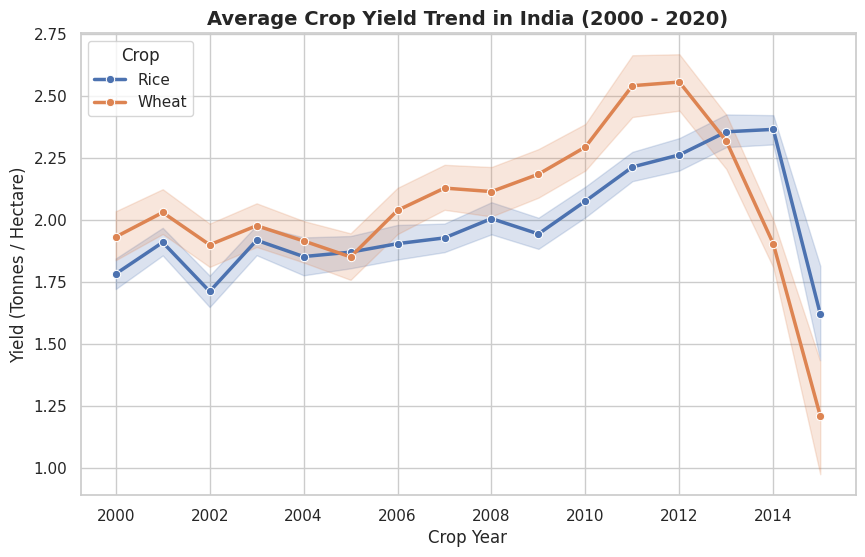

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual theme for our graphs
sns.set_theme(style="whitegrid")

# Create a figure canvas with a specific size
plt.figure(figsize=(10, 6))

# Create a line plot showing Yield over Crop_Year, separated by Crop type
sns.lineplot(
    data=df_final,
    x='Crop_Year',
    y='Yield',
    hue='Crop',
    marker='o',
    linewidth=2.5
)

# Add clear titles and axis labels
plt.title('Average Crop Yield Trend in India (2000 - 2020)', fontsize=14, fontweight='bold')
plt.xlabel('Crop Year', fontsize=12)
plt.ylabel('Yield (Tonnes / Hectare)', fontsize=12)

# Display the plot
plt.show()

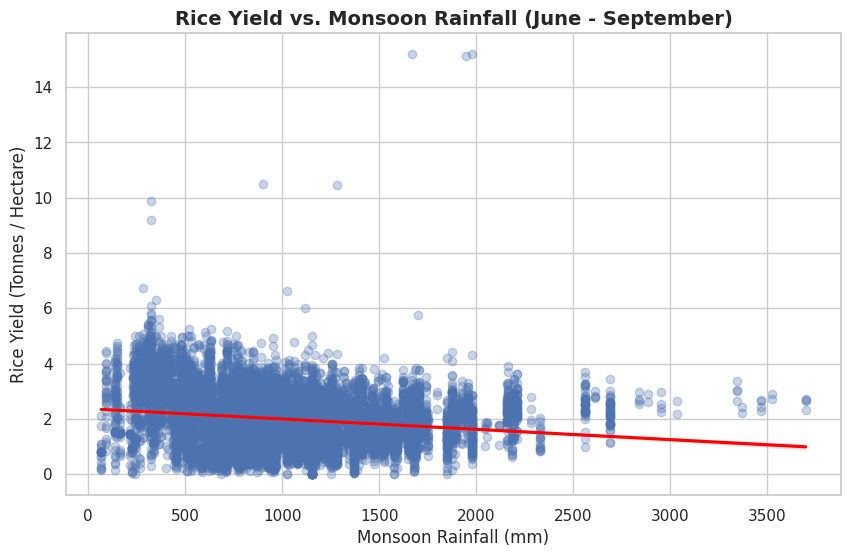

In [15]:
# 1. Filter our data for just 'Rice' to study its relationship with monsoon rainfall
df_rice = df_final[df_final['Crop'] == 'Rice'].copy()

# 2. Create a figure canvas
plt.figure(figsize=(10, 6))

# 3. Create a scatter plot with a trendline (regression line) using Seaborn
sns.regplot(
    data=df_rice,
    x='Jun-Sep',
    y='Yield',
    scatter_kws={'alpha': 0.3}, # Makes the dots slightly transparent so we can see density
    line_kws={'color': 'red'}   # Draws a red trend line to show the overall direction
)

# 4. Add titles and labels
plt.title('Rice Yield vs. Monsoon Rainfall (June - September)', fontsize=14, fontweight='bold')
plt.xlabel('Monsoon Rainfall (mm)', fontsize=12)
plt.ylabel('Rice Yield (Tonnes / Hectare)', fontsize=12)

# Display the plot
plt.show()

In [16]:
# Calculate the Pearson correlation coefficient between Monsoon Rainfall ('Jun-Sep') and Rice Yield
correlation_rice = df_rice['Jun-Sep'].corr(df_rice['Yield'], method='pearson')

print(f"Pearson Correlation between Monsoon Rainfall and Rice Yield: {correlation_rice:.4f}")

# Let's also check Wheat just for comparison (using Annual or winter rainfall)
df_wheat = df_final[df_final['Crop'] == 'Wheat'].copy()
correlation_wheat = df_wheat['ANNUAL'].corr(df_wheat['Yield'], method='pearson')
print(f"Pearson Correlation between Annual Rainfall and Wheat Yield: {correlation_wheat:.4f}")

Pearson Correlation between Monsoon Rainfall and Rice Yield: -0.1820
Pearson Correlation between Annual Rainfall and Wheat Yield: -0.4546
